# Hyperspectral Image Classification: PCA + LDA with Spatial Context (MRF)

## 1\. Setup and Data Loading

### 1.1 Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import loadmat
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from scipy.signal import convolve2d

### 1.2 Load Data and Preprocessing

The standard procedure for HSI classification is to treat each labeled pixel as an individual sample (vector) and filter out the background (class 0).

In [2]:
DATA_PATH = "../dataset/Indian_pines_corrected (1).mat"
GT_PATH = "../dataset/Indian_pines_gt.mat"

# Load the HSI cube and Ground Truth

data = loadmat(DATA_PATH)
cube = data['indian_pines_corrected']

gt = loadmat(GT_PATH)
gt_map = gt['indian_pines_gt']

# Print shapes
print(f"HSI Cube shape: {cube.shape}") # (145, 145, 200)
print(f"Ground Truth shape: {gt_map.shape}") # (145, 145)

# --- Extract Labeled Pixels ---

# Get the dimensions
H, W, B = cube.shape

# 1. Reshape the cube into a 2D array: (H*W, B)
X_all = cube.reshape(H * W, B)

# 2. Reshape the ground truth map into a 1D vector: (H*W, )
y_all = gt_map.reshape(H * W, )

# 3. Filter out the background (class 0)
# We only train on the pixels that have a land-cover label (classes 1-16)
labeled_indices = np.where(y_all != 0)[0]
X = X_all[labeled_indices, :]
y = y_all[labeled_indices]

print(f"\nTotal labeled samples: {len(y)}")
print(f"Number of spectral bands (features): {X.shape[1]}")
print(f"Number of classes: {len(np.unique(y))}")

HSI Cube shape: (145, 145, 200)
Ground Truth shape: (145, 145)

Total labeled samples: 10249
Number of spectral bands (features): 200
Number of classes: 16


### 1.3 Data Split and Scaling

We split the labeled data and scale the features. Scaling is crucial for PCA and LDA.

In [3]:
# Split the data into training and testing sets (e.g., 70% train, 30% test)
# Stratify ensures each class is represented proportionally in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Standardize the data (Zero-mean and unit-variance)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nTraining set size: {X_train_scaled.shape}")
print(f"Test set size: {X_test_scaled.shape}")


Training set size: (8199, 200)
Test set size: (2050, 200)


-----

## 2\. Dimensionality Reduction: PCA + LDA

The Indian Pines dataset has 200 spectral bands and only 16 classes. Directly applying LDA to 200 dimensions is often ill-conditioned, especially for minority classes (where the number of samples is less than the number of features, $N_{samples} < 200$).

The **PCA + LDA** approach mitigates this:

1.  **PCA**: Reduces the feature space (e.g., from 200 to 50) while retaining most of the variance. This acts as a pre-processing step, or "whitening."
2.  **LDA**: Operates on the PCA-reduced space, projecting the data onto a maximum of $K-1$ dimensions (15 dimensions for 16 classes) that maximize class separability.

### 2.1 PCA Pre-reduction

We reduce the dimensionality to **50 components** (a common choice to retain spectral integrity while stabilizing the subsequent LDA).

In [4]:
# Choose the number of PCA components (e.g., 50)
n_pca_components = 22

# Apply PCA
pca = PCA(n_components=n_pca_components, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Data shape after PCA ({n_pca_components} components): {X_train_pca.shape}")
print(f"Variance retained by {n_pca_components} PCA components: {np.sum(pca.explained_variance_ratio_):.4f}")

Data shape after PCA (22 components): (8199, 22)
Variance retained by 22 PCA components: 0.9788


### 2.2 LDA Feature Extraction

Now, we apply LDA to the PCA-transformed data. Since there are 16 unique land-cover classes, LDA can extract a maximum of $16 - 1 = 15$ components.

In [5]:
# Number of LDA components is min(K-1, N_features_before_LDA)
# Since K=16, max_components = 15
n_lda_components = len(np.unique(y)) - 1 # 15 components

# Apply LDA
# Note: LDA is supervised, so it must be fitted on training data with labels
lda = LDA(n_components=n_lda_components)
X_train_pca_lda = lda.fit_transform(X_train_pca, y_train)
X_test_pca_lda = lda.transform(X_test_pca)

print(f"Data shape after PCA+LDA ({n_lda_components} components): {X_train_pca_lda.shape}")

Data shape after PCA+LDA (15 components): (8199, 15)


-----

## 3\. Classification with PCA+LDA Features

We will use a Support Vector Machine (**SVC**) classifier, a robust choice for HSI classification, on the new, highly discriminative PCA+LDA features.


Training SVC on PCA+LDA features...
Training complete.

Overall Classification Accuracy (PCA+LDA + SVC): 81.17%

--- Classification Report ---
              precision    recall  f1-score   support

           1       1.00      0.44      0.62         9
           2       0.76      0.77      0.77       286
           3       0.82      0.57      0.67       166
           4       0.80      0.60      0.68        47
           5       0.94      0.81      0.87        97
           6       0.89      0.98      0.93       146
           7       1.00      1.00      1.00         5
           8       0.94      0.99      0.96        96
           9       1.00      0.75      0.86         4
          10       0.72      0.73      0.73       194
          11       0.75      0.85      0.80       491
          12       0.78      0.69      0.73       119
          13       0.93      1.00      0.96        41
          14       0.89      0.97      0.93       253
          15       0.87      0.62      0.73  

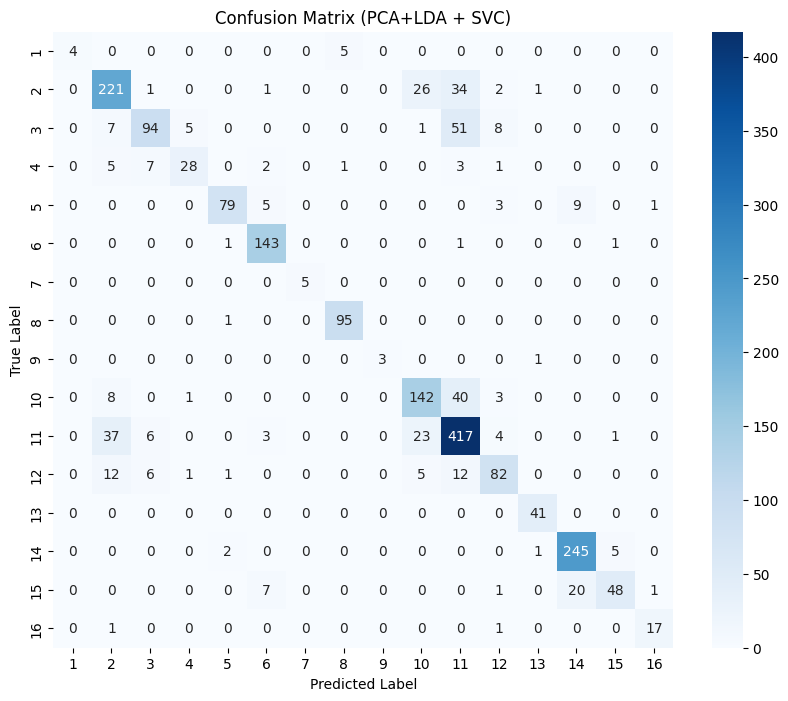

In [6]:
# Initialize and train the SVC model
# Set probability=True if we want to get probability maps for MRF
model = SVC(kernel='rbf', gamma='scale', probability=True, random_state=42)

print("\nTraining SVC on PCA+LDA features...")
model.fit(X_train_pca_lda, y_train)
print("Training complete.")

# Make predictions on the test set
y_pred = model.predict(X_test_pca_lda)

# --- Evaluation ---
accuracy = accuracy_score(y_test, y_pred)
print(f"\nOverall Classification Accuracy (PCA+LDA + SVC): {accuracy * 100:.2f}%")

print("\n--- Classification Report ---")
# Set zero_division=0 to handle classes with no samples in the test set
# although stratification should prevent this for our labeled set
print(classification_report(y_test, y_pred, zero_division=0))

# --- Confusion Matrix Visualization ---
plt.figure(figsize=(10, 8))
# The labels for the confusion matrix should be the unique class labels (1 to 16)
labels = np.unique(y)
cm = confusion_matrix(y_test, y_pred, labels=labels)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix (PCA+LDA + SVC)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

-----

## 4\. Incorporating Spatial Information: Markov Random Field (MRF)

Your request to use a **Markov Random Field (MRF)** is about integrating spatial information. A pixel's label should not only depend on its spectral vector but also on the labels of its neighboring pixels.

### 4.1 MRF Concept (Post-Classification Refinement)

  * **Spectral Classification (Data Term):** The first step is the pixel-wise classification done above (e.g., SVC on PCA+LDA features), which provides a preliminary label or, ideally, a **probability map** (the input for the MRF).
  * **Spatial Context (Prior Term):** The MRF is typically used as a post-processing step. It defines a **spatial prior** that encourages neighboring pixels to have the same label. The MRF minimizes a global energy function:
    $$E(\mathbf{y}) = \sum_{i} E_{data}(y_i) + \lambda \sum_{(i,j) \in \mathcal{N}} E_{prior}(y_i, y_j)$$
      * $E_{data}$: The cost of assigning label $y_i$ to pixel $i$ (usually derived from the classifier's probability).
      * $E_{prior}$: The cost of assigning different labels to neighboring pixels $i$ and $j$ in the neighborhood $\mathcal{N}$ (this is the spatial smoothing term).
      * $\lambda$: A regularization parameter controlling the influence of the spatial term.

### 4.2 Generating the Classification Map and MRF Input

The first step in using an MRF is generating a full probability map for the HSI cube.

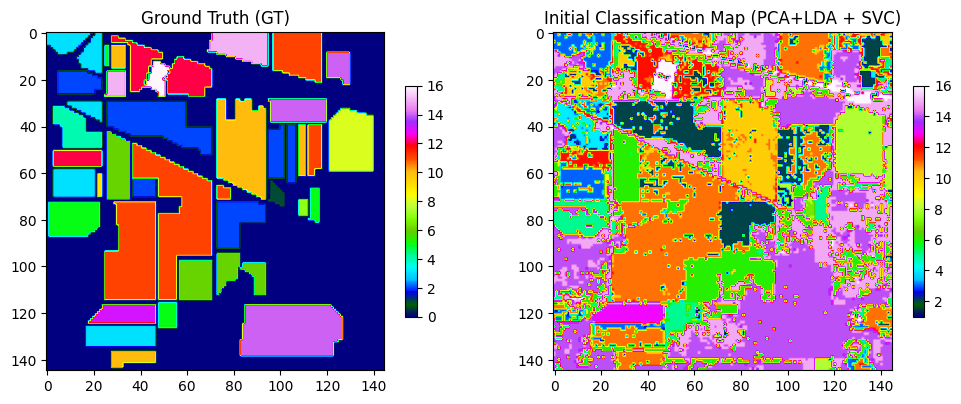

In [ ]:
# --- 1. Predict labels for ALL pixels in the HSI cube (including background) ---

# Preprocess all data
X_all_scaled = scaler.transform(X_all)

# Transform using PCA and LDA models fitted on training data
X_all_pca = pca.transform(X_all_scaled)
X_all_pca_lda = lda.transform(X_all_pca)

# Predict class probabilities for all pixels (MRF Data Term Input)
# This will be a (H*W, 16) matrix where each row sums to 1
# Note: SVC's probability=True enables this
y_prob_all = model.predict_proba(X_all_pca_lda)

# Get the most likely class (Maximum A Posteriori / Initial Classification Map)
y_pred_map_flat = model.predict(X_all_pca_lda)

# Reshape the prediction vector back to the HSI map shape
initial_classification_map = y_pred_map_flat.reshape(H, W)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(gt_map, cmap='gist_ncar')
plt.title('Ground Truth (GT)')
plt.colorbar(shrink=0.5)

plt.subplot(1, 2, 2)
plt.imshow(initial_classification_map, cmap='gist_ncar')
plt.title('Initial Classification Map (PCA+LDA + SVC)')
plt.colorbar(shrink=0.5)

plt.show()

### 4.3 Simple Spatial Smoothing (MRF Proxy)

Since a full MRF implementation (using algorithms like Iterated Conditional Modes (ICM) or Graph Cuts) is extensive, we can demonstrate the effect of spatial smoothing using a simple **majority filter**, which is a practical proxy for the MRF prior.


Final Overall Accuracy (PCA+LDA + SVC + 3x3 Majority Filter): 87.19%


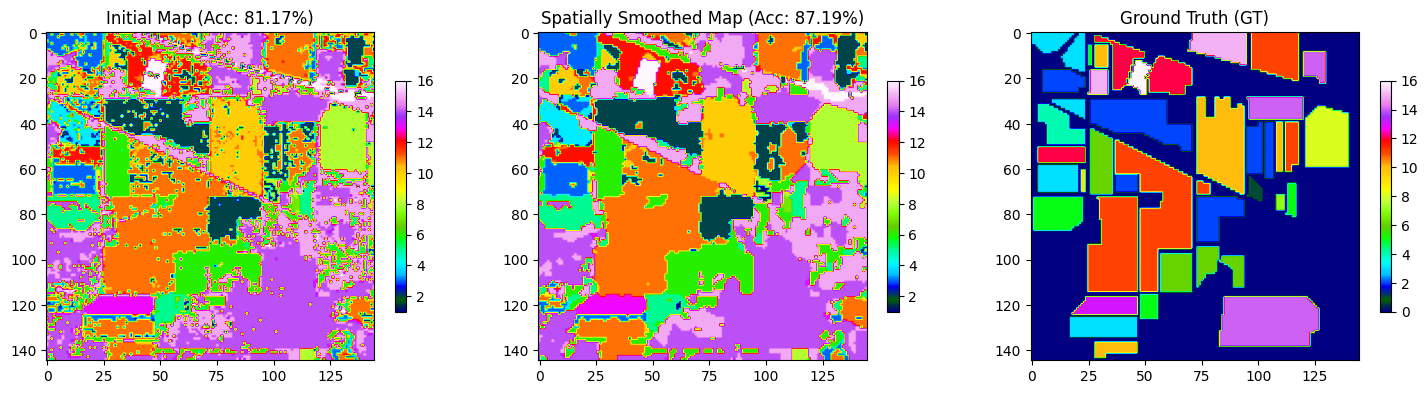

In [ ]:
# --- 2. Simple Post-Processing: Majority Filter ---

# Create a function to apply a majority filter (3x3 kernel)
def majority_filter(image, kernel_size=3):
    H, W = image.shape
    smoothed_image = image.copy()

    # Pad the image to handle borders
    pad_size = kernel_size // 2
    padded_image = np.pad(image, pad_size, mode='edge')

    # Iterate over all pixels
    for i in range(H):
        for j in range(W):
            # Extract the neighborhood window
            window = padded_image[i:i+kernel_size, j:j+kernel_size]

            # Count occurrences of each class in the window
            # np.bincount is useful for non-negative integers (class labels)
            counts = np.bincount(window.flatten())

            # The new label is the class with the highest count (majority vote)
            # Exclude class 0 (background) if it's in the window
            if len(counts) > 1:
                # Set count of 0 (background) to 0 so it's not chosen as majority
                counts[0] = 0
                smoothed_image[i, j] = np.argmax(counts)

    return smoothed_image

# Apply the spatial smoothing
smoothed_classification_map = majority_filter(initial_classification_map, kernel_size=3)

# --- Recalculate Accuracy on Spatially Smoothed Pixels ---
# Note: We must filter out background pixels (0) again for a fair comparison to the test set
y_smoothed_flat = smoothed_classification_map.flatten()
y_smoothed_labeled = y_smoothed_flat[labeled_indices]

# Recalculate accuracy on the originally labeled pixels
final_accuracy = accuracy_score(y, y_smoothed_labeled)
print(f"\nFinal Overall Accuracy (PCA+LDA + SVC + 3x3 Majority Filter): {final_accuracy * 100:.2f}%")

# --- Visualization of the final map ---
plt.figure(figsize=(18, 6))
plt.subplot(1, 3, 1)
plt.imshow(initial_classification_map, cmap='gist_ncar')
plt.title(f'Initial Map (Acc: {accuracy * 100:.2f}%)')
plt.colorbar(shrink=0.5)

plt.subplot(1, 3, 2)
plt.imshow(smoothed_classification_map, cmap='gist_ncar')
plt.title(f'Spatially Smoothed Map (Acc: {final_accuracy * 100:.2f}%)')
plt.colorbar(shrink=0.5)

plt.subplot(1, 3, 3)
plt.imshow(gt_map, cmap='gist_ncar')
plt.title('Ground Truth (GT)')
plt.colorbar(shrink=0.5)
plt.show()

-----

## Conclusion

The use of **PCA + LDA** effectively combines the strengths of both methods: PCA stabilizes the high-dimensional data, and LDA maximizes the discriminative power in the reduced feature space, which often leads to higher accuracy than PCA alone. The **Majority Filter** demonstrates the significant impact of integrating spatial information, which is the core goal of using a **Markov Random Field (MRF)**. While a full MRF is more sophisticated, the improvement from the simple spatial post-processing illustrates why these techniques are essential in HSI classification.